# Final report extrapolations

Stimuli the fish were never shown, simulated with the trained models: **two dot groups at once** and **several simulated
fish in one dish, each seeing the others as dots**. The data contain neither, so these are predictions: what the models
do is fixed by the rule that turns the scene into the network's input, and every result is read against references on
the same scenes (a fish shown one group, a fish shown neither).

The three final-report notebooks: `Final_report_models.ipynb` (the model sequence), `Final_report_ablations.ipynb`
(the ablation study on the analysis model 26e), `Final_report_extrapolations.ipynb` (two dot groups, several fish). The full
development history stays in `Report_models.ipynb`.

## Contents

1. [Two dot groups at once](#two-groups)
2. [Several fish: do they shoal?](#multi-fish) — yes; pairs, groups of 5 and 10, a 5× dish, videos
3. [With repulsion](#repulsion) — F + the turn-away term fitted to the Larsch screen data, the same scenes

In [ ]:
# Setup: the evaluation code lives in ../scripts.
import sys; sys.path.insert(0, "."); sys.path.insert(0, "../scripts")
import numpy as np, pandas as pd
pd.set_option("display.width", 250)
from rollout_model1_local import run
from model_figures import window_stats_grid, dot_profile, attraction_table, toward_by_n
from input_ablation import profile_variants_matched
REJ = {"wall_reject": {"d0": 2.0, "d1": 10.0, "max_draws": 20}}   # generation-time wall containment (Models 2+)

<a id="two-groups"></a>
## 1. two dot groups at once: averaging or choosing?

The recorded programme never shows two dot groups at the same time (0 % of 39,542 stimulus bouts have dots on both
sides), so how a trained model responds to two groups is **not learned**: it is fixed by the rule that turns two groups
into the network's input. Four rules, all on the same trained weights, no retraining:

| Rule | What the network is given | Inputs stay valid? | Hypothesis |
|---|---|---|---|
| **effects** (main) | each group alone, plus a no-dots baseline; every head's output = baseline + the sum of the groups' effects | yes | independent pulls that add |
| **add** | one row with the groups' stimulus columns summed | no (cos > 1 etc.) | drives add before the nonlinearity, so groups can interact |
| **avg** | one row with the columns averaged | yes | averaging (close to the old one-centroid code) |
| **nearest** | the nearest group only | yes | winner-take-all |

With one group every rule gives exactly the standard input, so every model's single-group behaviour is unchanged:
checked bit for bit (below). The profile correction is evaluated on each group's own features and summed (effects /
add), averaged (avg) or taken from the nearest group; the aligned-and-far flag of a combined row is the max over groups;
the block clock is shared (time since the scene's onset).

**Models:** 28b (26e + pf-B with the 20 s cut-off, final step: the no-drift model) and 14f (Model 17 + the same
correction: the best model overall). 50 simulated fish per scene and condition (10 per fold model), each with its own
latent draw; the same fish (start pose, latent, drift, per-block random streams, dot tracks) under every condition, so
every comparison is paired by fish.

**Scenes:** a 100 s lead-in pause, then 10 blocks of 60 s with two groups and a 50 s pause. At each block onset group A
is placed at bearing +θ and distance d_A from the fish, group B at −θ, d_B; A swaps sides every block. Each group is a
whole recorded dot group of its condition, rotated about the fish's onset point to the bearing and **scaled** about it
to the distance (its path relative to the fish keeps the recorded shape); templates = every recorded block of the
condition that started 14–28 mm out, right-side recordings mirrored, drawn at random per fish, block and group; two
groups of the same condition are exact mirror images, so a symmetric scene is exactly symmetric. Sweeps: angular
separation 2θ = 30–180° (4 v 4 moving, 20 mm); counts 2 v 8, 2 v 4, 4 v 8 (moving, ±90°, 20 mm); near (14 mm) v far
(27 mm); a 2-dot v 8-dot grid over both distances (14 / 20 / 27 mm); moving v static (4 v 4, 8 v 8).

**References, on the same tracks:** every scene is also run with only A shown, only B shown and neither (the hidden
groups are computed but never given to the model). The side index has a geometric floor — two groups 30° apart are only
11 mm apart, so even a fish committed to one of them often scores "between" — and the placement alone favours some
groups; every two-group number is therefore read **against these references**, paired by fish.

**Readouts per trial (block):** side index SI = (d_B − d_A)/(d_A + d_B) (+1 at A, −1 at B); **choice** = sign of the
mean SI over 20–60 s, *between* if |mean SI| < 0.2; late (20–60 s) distance to the **nearer** and the **farther** group
(choosing = near small and far large; averaging = both moderate; ignoring = both large); **decision** = |SI| > 0.5 for
10 s, as the fraction of all trials decided by time t; the turn toward each group. P(A), P(B), P(between) = mean over
simulated fish of each fish's fractions, 95 % bootstrap CI over fish. Trials are kept when both groups start inside the
dish and stay inside for ≥ 3/4 of 20–60 s (`dropped_pct`; set by the placement, not by behaviour).

These are predictions, not fits: any of the four rules is consistent with every recorded bout. A two-group experiment
would decide between them. (Version 2: the first version translated the tracks instead of scaling them, used 6 fixed
track pairs and had no references, which biased the side choices and the distance and grid readouts; its outputs are
kept in `multi_stim_v1/`.)

In [ ]:
# Model 31: validation -- with ONE group shown, every rule reproduces the standard simulator bit for bit (the
# recorded programme, first 30 min, and a scene with only A shown, 3 fish per model); a hidden group changes nothing;
# symmetric scenes are exactly symmetric at onset; every two-group run is finite and differs.
import json
import multi_stim as MS
print(json.dumps(json.load(open(MS.OUT / "validation.json")), indent=1))

{
 "28b": {
  "programme/effects": true,
  "programme/add": true,
  "programme/avg": true,
  "programme/nearest": true,
  "A only/effects": true,
  "A only/add": true,
  "A only/avg": true,
  "A only/nearest": true,
  "phantom B changes nothing": true,
  "two groups run/effects": true,
  "symmetric scene: |dA - dB| at onset < 1e-9 px": true,
  "two groups run/add": true,
  "two groups run/avg": true,
  "two groups run/nearest": true
 },
 "14f": {
  "programme/effects": true,
  "programme/add": true,
  "programme/avg": true,
  "programme/nearest": true,
  "A only/effects": true,
  "A only/add": true,
  "A only/avg": true,
  "A only/nearest": true,
  "phantom B changes nothing": true,
  "two groups run/effects": true,
  "symmetric scene: |dA - dB| at onset < 1e-9 px": true,
  "two groups run/add": true,
  "two groups run/avg": true,
  "two groups run/nearest": true
 }
}


In [ ]:
# Model 31: per scene and condition (the four rules, then only A shown / only B shown / neither shown).
# P_* = mean over simulated fish of each fish's fraction of kept trials; d_near / d_far = late (20-60 s) distance to the
# nearer / farther group (mm); decided = fraction of trials with |SI| > 0.5 for 10 s. For the rules, paired by fish
# against the references: dbtw_chooser = P(between) minus a fish shown one group (> 0: more often between than a
# committed fish); pref_corr = P(A) - P(B) minus that of a fish shown neither (the preference beyond the placement);
# [lo, hi] = 95 % CI over fish.
S31 = MS.summary_table()
S31.to_csv(MS.OUT / "summary_table.csv", index=False)
pd.set_option("display.max_rows", 400)
_c = ["P_A", "P_between", "P_B", "d_near_late", "d_far_late", "decided", "n_trials", "dropped_pct",
      "dbtw_chooser", "dbtw_chooser_lo", "dbtw_chooser_hi", "pref_corr", "pref_corr_lo", "pref_corr_hi"]
for _tag in ("28b", "14f"):
    _t = S31[S31.model == _tag].set_index(["sweep", "scene", "cond"])[_c]
    print(MS.MODEL_LABEL[_tag]); print(_t.round(3).to_string()); print()

28b: 26e + correction (no drift)
                                  P_A  P_between    P_B  d_near_late  d_far_late  decided  n_trials  dropped_pct  dbtw_chooser  dbtw_chooser_lo  dbtw_chooser_hi  pref_corr  pref_corr_lo  pref_corr_hi
sweep    scene        cond                                                                                                                                                                             
angle    ang30        effects   0.118      0.782  0.100       10.851      17.615    0.156       418         16.4         0.051            0.004            0.098     -0.021        -0.088         0.044
                      add       0.075      0.833  0.091       10.511      16.756    0.123       390         22.0         0.103            0.057            0.146     -0.055        -0.111        -0.002
                      avg       0.098      0.803  0.099       15.769      22.382    0.104       383         23.4         0.073            0.024            0.119     -0

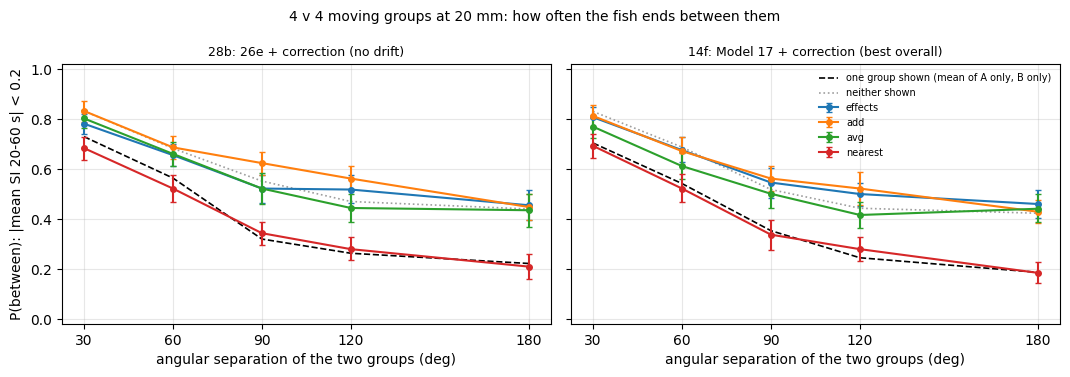

In [ ]:
# Model 31: angular separation (4 v 4 moving at 20 mm) -- P(between) per rule against a fish shown one group (dashed)
# and a fish shown neither (dotted), on the same tracks. Both references fall with separation (geometry): read the gap.
MS.plot_angle(S31);

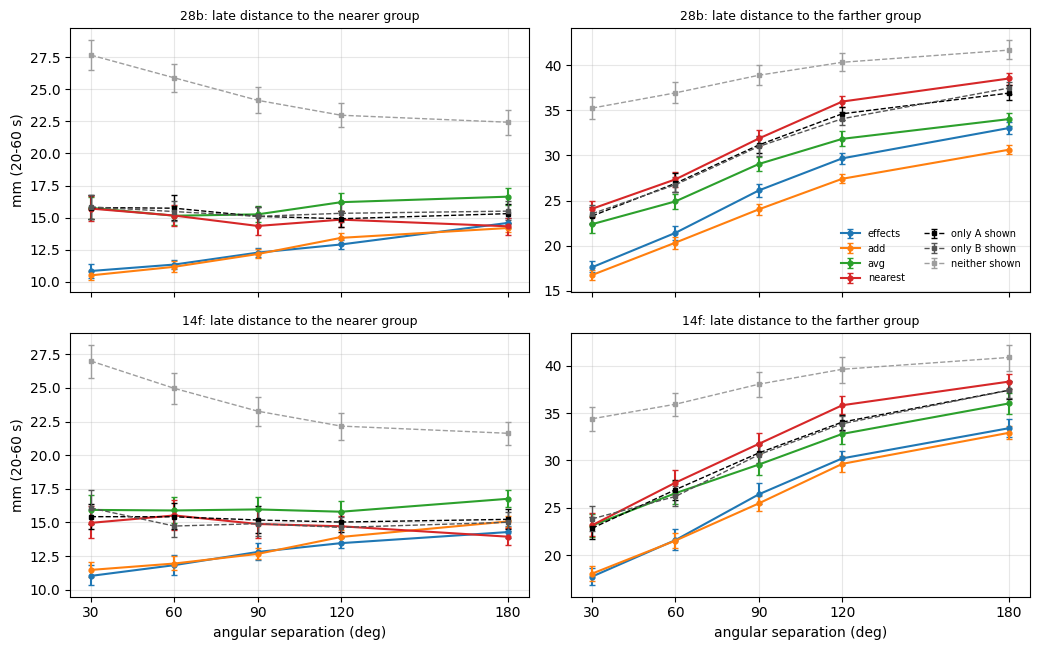

In [ ]:
# Model 31: late distance to the nearer and to the farther group by separation: choosing = near small and far large;
# averaging = both moderate (closer to both than a committed fish); ignoring = both large (the neither-shown reference).
MS.plot_late_distances(S31);

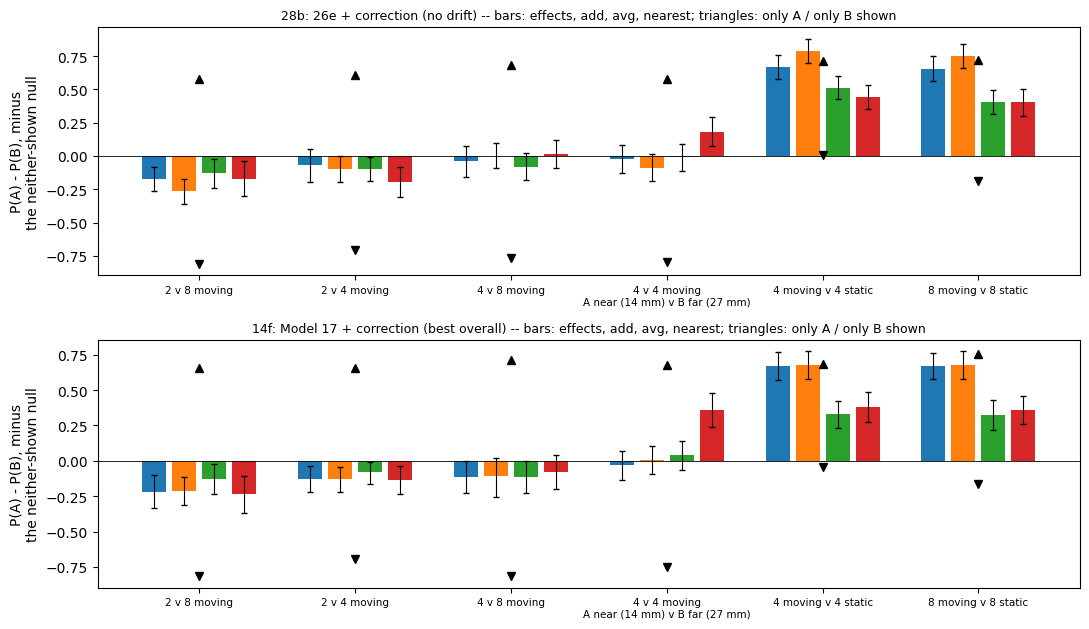

In [ ]:
# Model 31: count, distance and motion -- P(A) - P(B) beyond the placement (minus a fish shown neither), A = the
# first-named group (the smaller, the nearer, the moving one); triangles = a fish shown only A / only B (the most a
# fully committed fish shows on these tracks).
MS.plot_preference(S31);

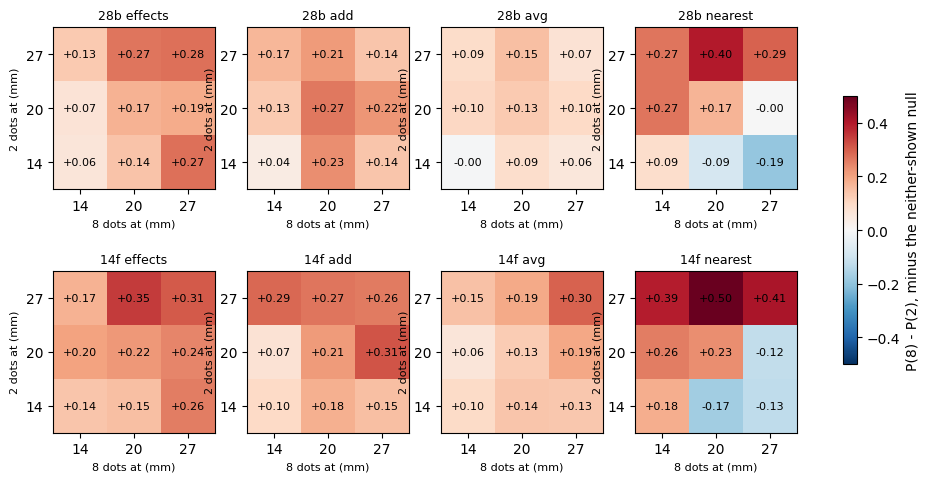

In [ ]:
# Model 31: count against distance -- P(8 dots) - P(2 dots) beyond the placement, each group at 14, 20 or 27 mm.
MS.plot_grid(S31);

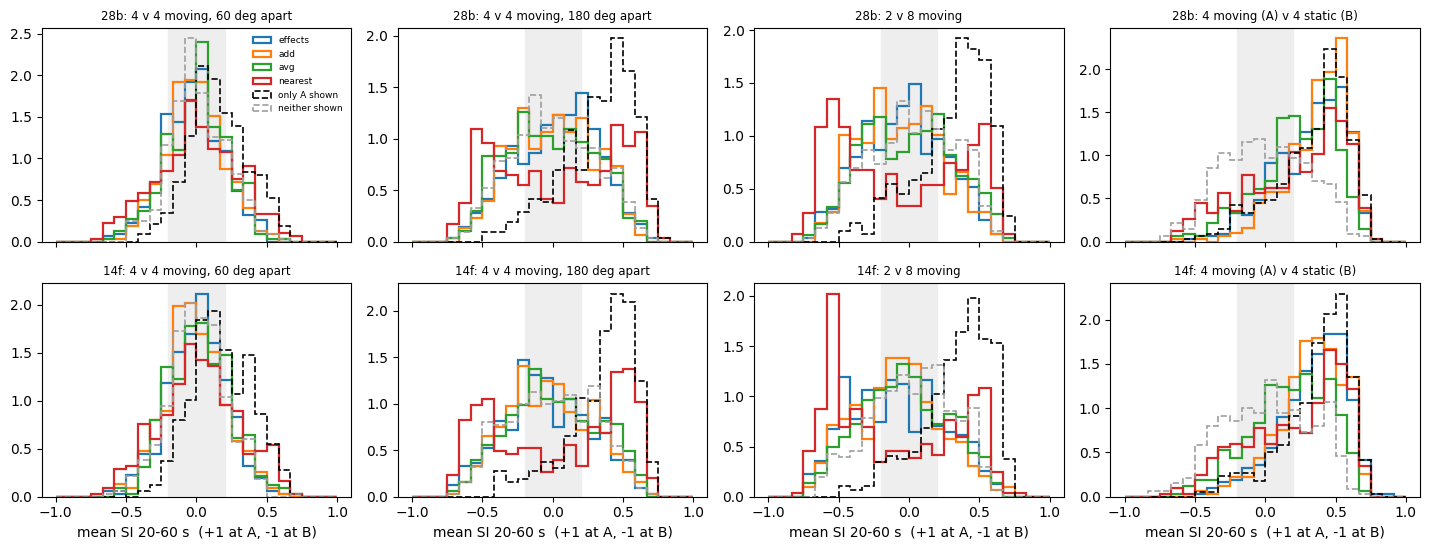

In [ ]:
# Model 31: per trial, the mean SI over 20-60 s, with a fish shown only A (black dashed) and shown neither (grey).
MS.plot_si_hist(scene_names=("ang60", "ang180", "n2v8", "mv4_st4"));

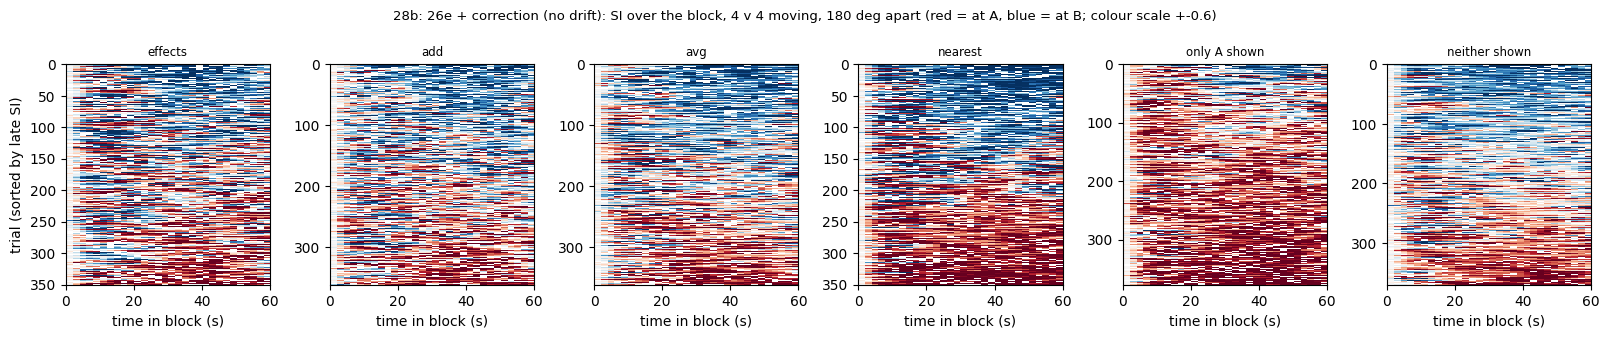

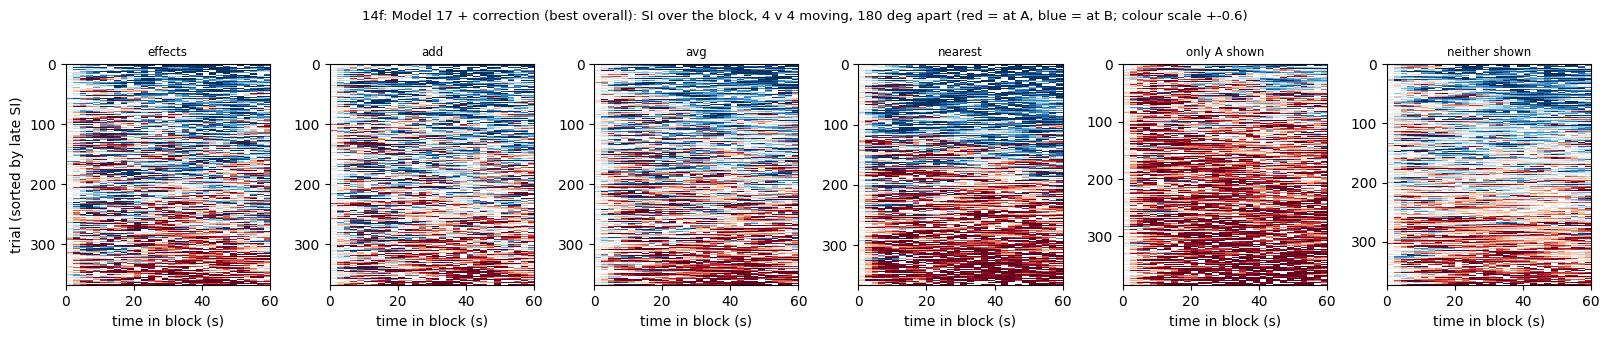

In [ ]:
# Model 31: SI over the block, one row per kept trial (sorted), 4 v 4 at 180 deg, with the references.
for _tag in ("28b", "14f"):
    MS.plot_si_heat(_tag, "ang180")

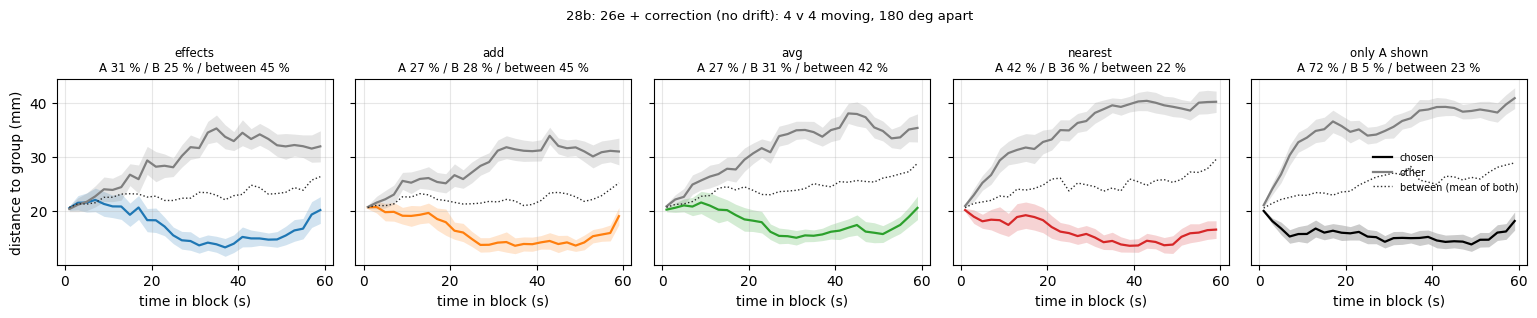

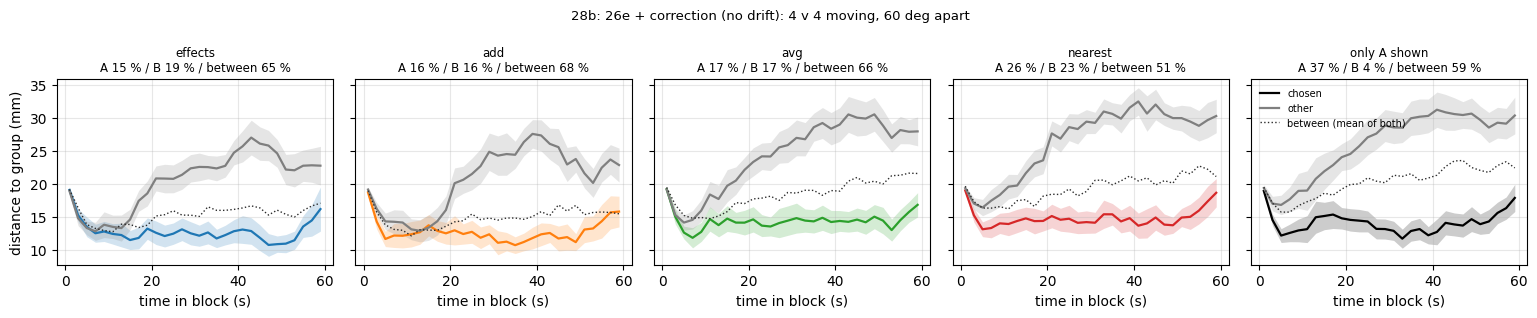

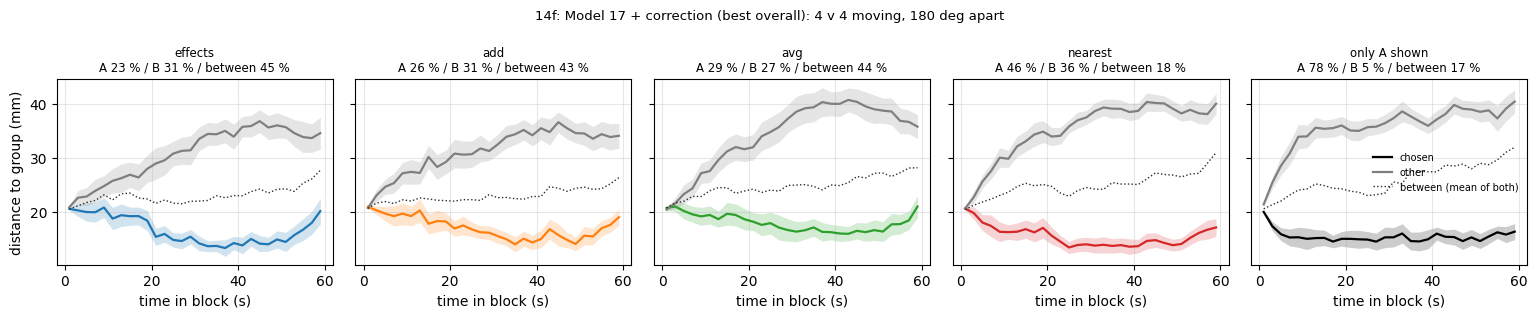

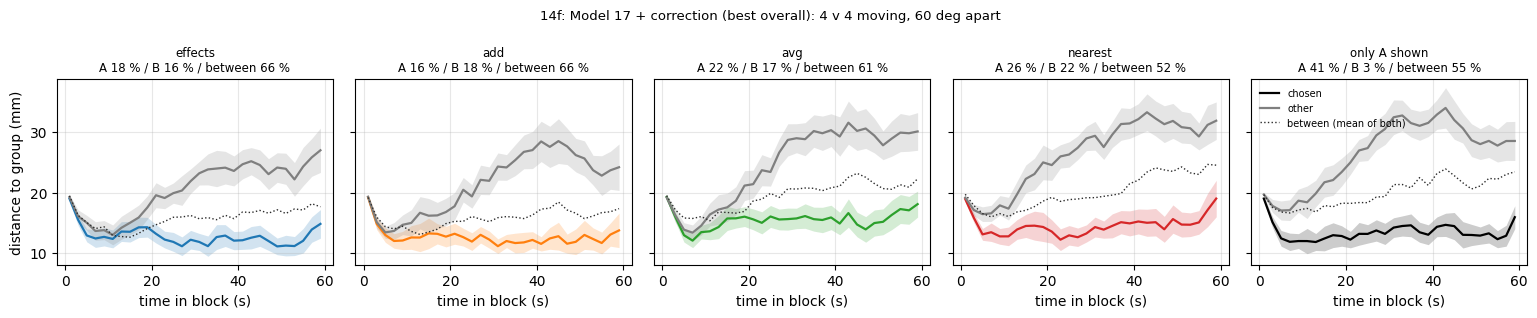

In [ ]:
# Model 31: distance to the chosen and to the other group over the block, next to the same split of a fish shown only
# A (selected by the same SI rule, so the curves compare fairly); dotted = the trials that stayed between.
for _tag in ("28b", "14f"):
    MS.plot_dist_by_choice(_tag, "ang180")
    MS.plot_dist_by_choice(_tag, "ang60")

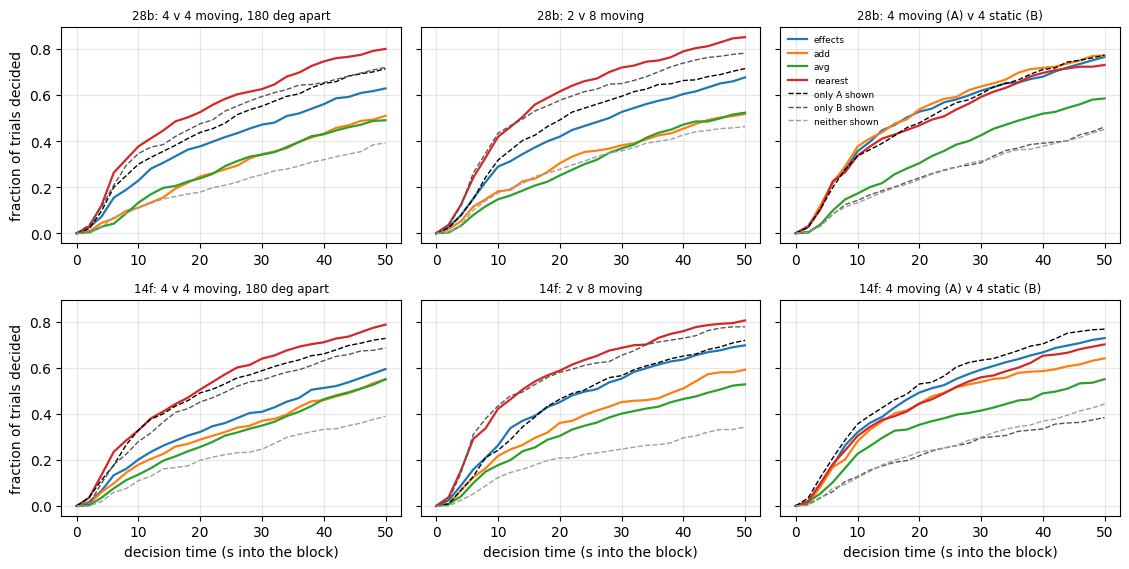

In [ ]:
# Model 31: fraction of all kept trials decided by time t (|SI| > 0.5 for 10 s), per rule and reference.
MS.plot_decision();

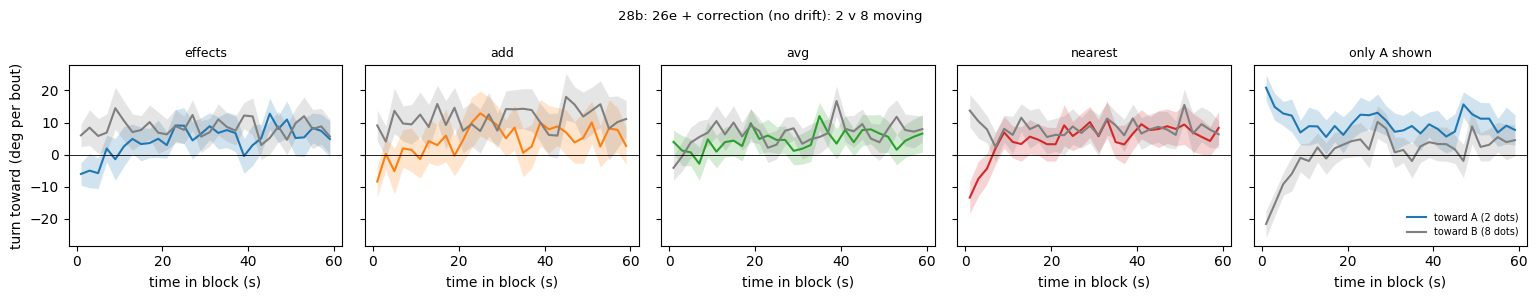

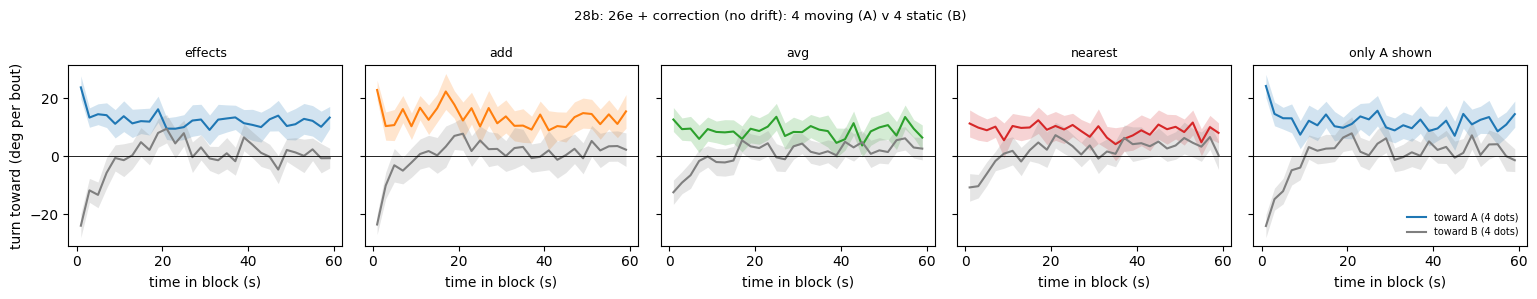

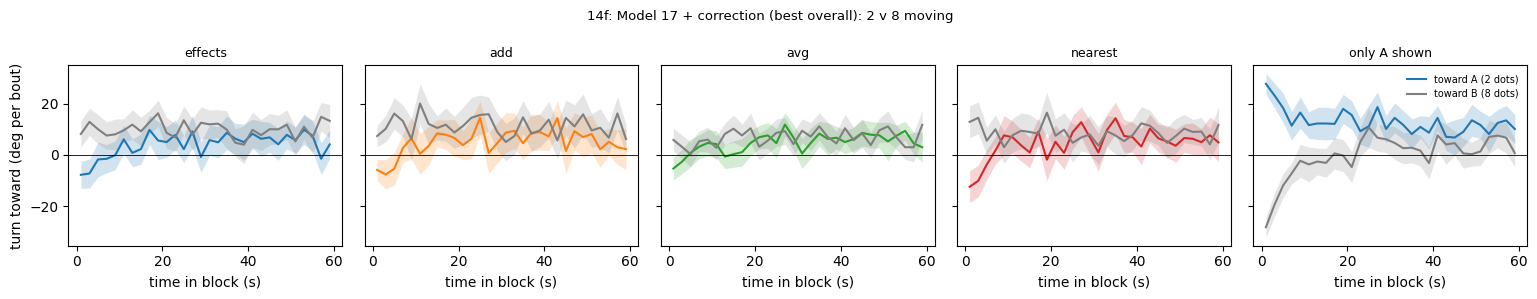

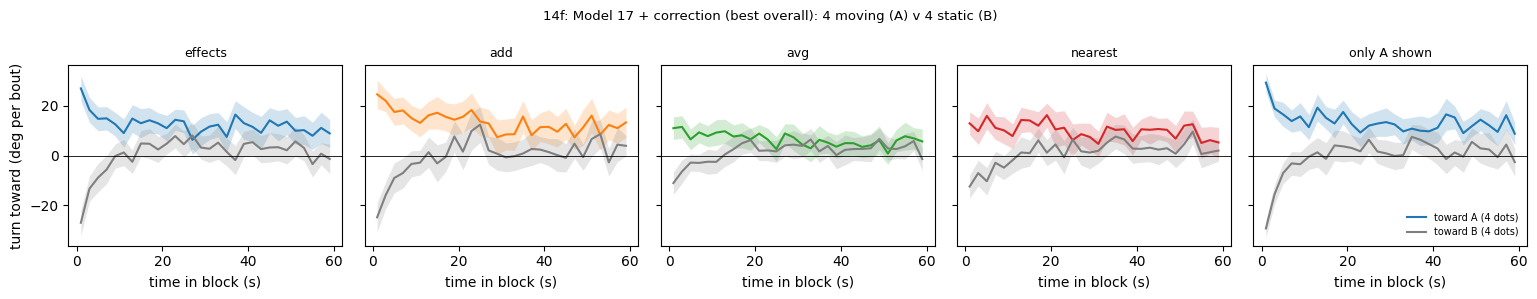

In [ ]:
# Model 31: the turn toward each group over the block (deg per bout), 2 v 8 and moving v static; last panel = a fish
# shown only A (its turn toward B, which it cannot see, is the null).
for _tag in ("28b", "14f"):
    MS.plot_toward(_tag, "n2v8")
    MS.plot_toward(_tag, "mv4_st4")

<a id="multi-fish"></a>
## 2. Several fish: do they shoal?

**Question.** If simulated fish see each other the way the real fish saw the projected dots, do they form shoals — and
do the shoals move together?

**How each fish sees the others** (`scripts/multi_fish.py`). Every fish runs the final model F unchanged; only what it is
shown is new. At each of its bouts it sees every other fish within 78 mm, at any bearing, always as **moving** dots. 78 mm
is where the model's log-range input saturates: beyond it the model's pull would stay constant rather than fade, so the
horizon is our choice (it keeps every input inside the trained values); in the training dish it hides only the rare
neighbour 78–98 mm away. Neighbours that are close to each other are pooled into one dot group of that
size — 3 fish close together = a 3-dot group at their centre — as long as they are no more spread out than a trained dot
group of that size was (≤ 10 mm from the centre for 2 dots … ≤ 21 mm for 8); the count is capped at 8. The groups are
combined by the two rules of the two-group experiment: **effects** (each group's effect added) and **nearest** (the
nearest group only). The 'dots just appeared' clock is held at its late-block value (a neighbour has no onset), so F's
correction term — which acts only in the first 20 s of a block — is inactive here; F's network weights are its own.

**Coupling.** The fish are simulated together: the fish whose next bout is earliest moves next and sees the others where
they are at that moment. Collisions are ignored (dots overlapped freely in training). Bouts are instantaneous.

**Pairing.** Every fish of a seed is fixed by (dish, fish): the same start, latent and random stream in every condition,
so conditions pair dish by dish, and a pair is fish 0–1 of the corresponding blind dish of 10.

**How to read it.**
- **Nulls are recomputed from our own simulations**, as in the papers: for pairs, each fish against its partner's track
  shifted in time by 1–10 min (Larsch & Baier 2018); for groups, pseudo-groups of fish taken from *different* dishes of
  the same condition, overlaid in time (Harpaz et al. 2021). Both keep each fish's own space use and kinematics.
- **D = ln(nearest-neighbour distance / that of the pseudo-groups)**: < 0 = closer together than chance. The blind fish
  give the occupancy part: fish that see moving neighbours also change where they swim in the dish, which moves
  distances even without attraction to particular fish.
- **Random directions** (control): the same scene, but every neighbour group is shown at a random bearing, redrawn every
  bout (same range, count and number of groups). Shoaling that survives this is not attraction.
- Readouts start at minute 5 (training dish) or 10 (5× dish). Seed 0 and seed 101 are separate fold sets, never pooled.
- Distances in mm at 3.60 px/mm.

### In short

**Yes — the model's fish shoal when they see each other, and in a large dish the shoals travel together.** Final model F
at seed 0 unless stated; every result below holds at seed 101 where it was run.

- **Pairs stay together.** The two fish are a median 14.5 mm apart, against 26.1 mm when the partner's track is shifted
  in time; attraction index +0.35 [0.33, 0.36] (seed 101: +0.32 [0.30, 0.34]). The same two fish blind: 29.2 mm, index
  0.00. Every fold of both seeds is positive (+0.27 to +0.37).
- **Groups are closer together than chance.** Training dish: D = −0.30 (5 fish) and −0.20 (10 fish), the same under
  'nearest' (−0.29, −0.20); seed 101 (10 fish): −0.18. Blind fish: D ≈ 0. The interval of every coupled condition is
  below 0, and so is D against a within-group time shift and against a fold-matched null.
- **It is attraction, not a side effect of the rule.** With every neighbour group shown in a random direction (same
  range, count and number of groups), D = −0.01 [−0.02, 0.00]: the aggregation needs the neighbours' direction. On top
  of the attraction, fish that see neighbours gather toward the dish centre (occupancy part −0.12 to −0.33 in ln
  distance); the null keeps that part out of D.
- **In the 5× dish, shoals form from a scattered start and move as one.** D = −0.76 [−0.89, −0.57] ('effects') and
  −0.40 [−0.47, −0.31] ('nearest'). Under 'effects' the largest shoal holds 8.3 of the 10 fish on average (fish of
  different dishes overlaid: 5.1; blind: 3.8), and half the fish or more are together 88 % of the time (59 %, 29 %). Two
  fish travel 4.7 m per pair-hour while staying within 25 mm of each other, against 1.3 m for fish of different dishes
  and 0.75 m blind; single episodes reach 0.5 m. In the formation video all 10 fish are together within 3 min of a
  scattered start.
- **Rules.** 'effects' (each neighbour group adds its pull) gives tighter, more persistent shoals than 'nearest' in the
  large dish; in the training dish the two tie. The fold models differ in how tight their shoals get in the large dish
  (D per fold −0.31 to −1.15), all negative.

**Next to the literature** (same definitions, nulls recomputed from our simulations; table 2.6). The training-dish D
(−0.18 to −0.30) lies between Harpaz et al.'s 14-dpf (−0.10) and 21-dpf (−0.55) real groups and far from their 7-dpf
larvae, which are slightly over-dispersed (+0.08). The pair attraction is weaker than Larsch & Baier's 26-dpf pairs (14.5
against 26 mm here; 5–20 against 40 mm there). Alignment barely exceeds chance (5 fish: 0.418 against 0.402), the level
of Harpaz's 7-dpf fish — the model has no input for a neighbour's heading, so it cannot align except by following. This
is juvenile-like aggregation, consistent with what the protocol and the real dot response suggest (roughly 2–3 weeks);
an age cannot be read off it, because D depends on the arena (−0.2 here, −0.4 to −0.76 in the 5× dish) and on the rule.

**Limits.** To the model a neighbour is a moving dot: no body, no heading, never pausing (real fish are still ~30 % of
the time), and collisions are ignored. In groups of 10 in the training dish the nine neighbours are often pooled into
one group, and on 39 % of bouts that pool has 9 fish shown as 8 dots — beyond the trained counts. Fish in groups take
steps 7–16 % longer than blind (real fish +3 % when moving dots appear, 90th percentile +8 %). The 78 mm view is a
choice (the model's pull does not fade there). In the 5× dish the model's wall cues are those of the training dish
magnified 5×, and no experiment has a counterpart. One model at two seeds; F's correction term is inactive with the
late clock.

In [ ]:
# Several fish: everything below is read from Model/multi_fish/ (scripts/multi_fish.py --run / --analyse)
import json
import multi_fish as MFish
S = MFish.load_summary()

### 2.1 The conditions

In [ ]:
MFish.conditions_table(S)

                                                         what        model  dish radius (mm)  fish per dish  dishes  minutes  readout from (min)  fish see each other                         rule   bouts  CPU h
condition                                                                                                                                                                                                        
A1_blind                           blind fish (training dish)    F, seed 0                49             10      50     30.0                 5.0                False                            -  674353  0.199
A1_pairs                                                pairs    F, seed 0                49              2      50     30.0                 5.0                 True                      effects  127045  0.085
A1_N5_effects                                 5 fish, effects    F, seed 0                49              5      20     30.0                 5.0                

### 2.2 Checks

The simulator itself: the new clock option changes nothing when unused, a coupled fish is exactly the generator run on a
replay of its partner, runs are reproducible, and fish pair across conditions.

In [ ]:
MFish.checks_table()

                                                                                                            passed
check                                                                                                             
generator hook: a provider-set block time equal to the generator's own gives the same fish bit for bit        True
coupling: a coupled fish == the generator run alone on a replay of its partner's track (2 rules x 3 pairs)    True
determinism: a group of 10 run twice is identical                                                             True
pairing: a blind fish is the same fish in a group of 10 and in a pair                                         True
two-group simulator (multi_stim.validate) still bit-identical after the hook                                  True


**Rule check.** Phantom moving neighbours on one side (10–25 mm, 60–120°, re-placed every bout), pooled and combined
exactly as in the shoal runs: does the fish turn toward them as real fish turn toward moving dots, and do its kinematics
stay sane? (k = 0: the same fish with nothing in view.)

In [ ]:
MFish.rules_table()

                            P(turn toward)  bouts / s  median step (mm)  mean |turn| (deg) real P(toward), same count
rule    phantom neighbours                                                                                           
effects 0                              NaN      0.813             3.833             40.917                          -
        1                            0.666      0.794             3.965             45.418             0.696 +- 0.021
        2                            0.694      0.781             3.935             45.203             0.728 +- 0.025
        3                            0.698      0.775             3.967             46.191         3 dots never shown
        4                            0.715      0.762             3.987             47.462             0.720 +- 0.040
        6                            0.722      0.773             4.193             48.162             0.732 +- 0.027
        9                            0.722      0.760   

### 2.3 Pairs

In [ ]:
MFish.pairs_table(S)

                                             attraction index [95% CI] median distance (mm) median distance, partner time-shifted (mm) time within 10 mm time within 25 mm                    per-fold AI
pairs            fish                                                                                                                                                                                    
pairs            see each other                +0.346 [+0.329, +0.363]                 14.5                                       26.1             0.287             0.773  +0.37 +0.30 +0.35 +0.36 +0.35
                 blind (same fish)             +0.003 [-0.009, +0.014]                 29.2                                       29.4             0.081             0.406  +0.00 -0.01 +0.01 +0.01 -0.00
                 difference (paired by pair)   +0.344 [+0.323, +0.364]                                                                                                                          

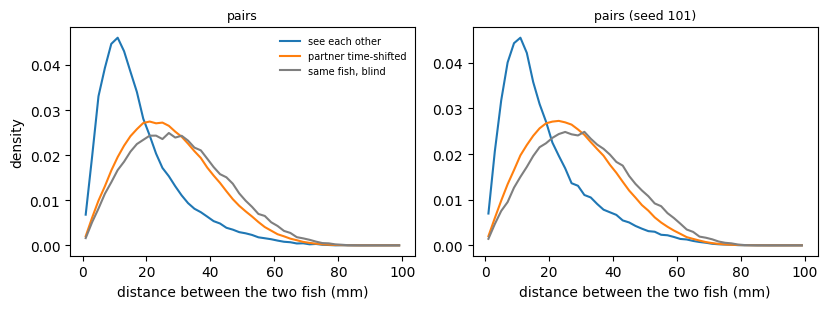

In [ ]:
MFish.plot_pair_distance();

### 2.4 Groups of 5 and 10 (training dish)

In [ ]:
MFish.groups_table(S)

                                    NN distance (mm): see / shuffled / blind D = ln(NN / NN shuffled) [95% CI]  D, SD over dishes  D vs time-shifted group D vs fold-matched null (sensitivity) D of the blind fish (should be ~0)  occupancy part ln(NN shuffled / NN blind)  mean distance ratio (Buske) largest shoal (fish): see / shuffled / blind time >= half the fish together: see / shuffled / blind alignment: see / shuffled                     per-fold D
condition                                                                                                                                                                                                                                                                                                                                                                                                                                                              
5 fish, effects                                            9.8 / 13.2 / 16.8           -

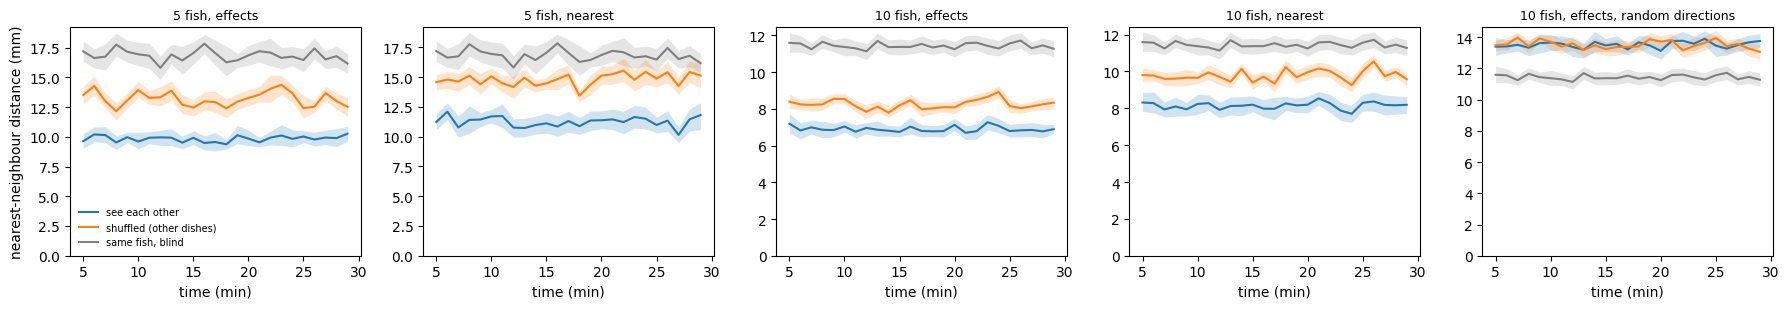

In [ ]:
MFish.plot_nn_time(S, [c for c in S["groups"] if MFish.CONDS[c]["arena"] == 1 and MFish.CONDS[c]["tag"] == "14f"]);

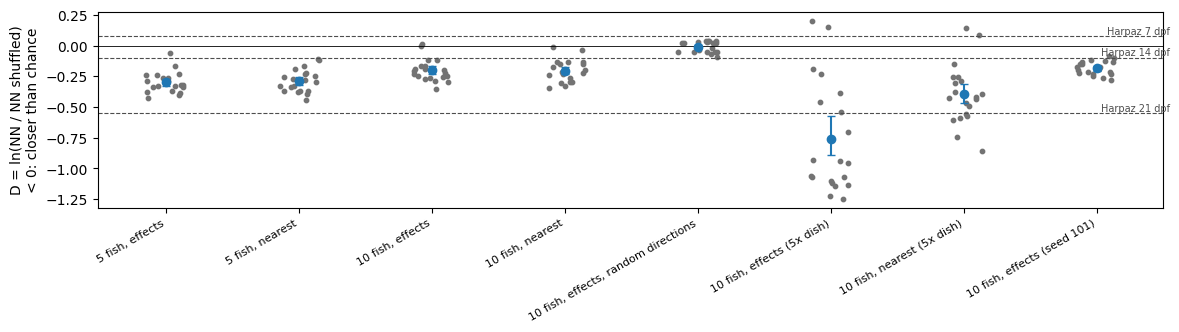

In [ ]:
MFish.plot_D(S);

### 2.5 The 5× dish (radius 244 mm, 60 min)

Blind fish use the inner part of this dish (90 % of bouts within ~100 mm of the centre, against 36 mm in the training
dish), so fish can lose sight of each other (78 mm) and meet again, and a shoal has room to travel. Every wall input of the
model is relative to the dish radius (the distance (R − r)/R, the rejection band, the start positions), so the fish
senses the wall as in the training dish magnified 5×; steps, the 78 mm view and the 25 mm shoal criterion are absolute.

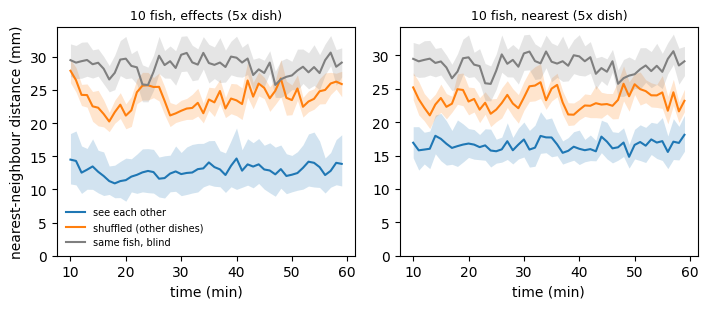

In [ ]:
MFish.plot_nn_time(S, [c for c in S["groups"] if MFish.CONDS[c]["arena"] == 5]);

**Travelling together.** Episodes in which two fish stay within 25 mm of each other; the distance their midpoint covers.

In [ ]:
MFish.cotravel_table(S)

                                                        mm travelled together per pair-hour  episodes per pair-hour  longest episode (mm)  95th percentile (mm)
condition                  fish                                                                                                                                
10 fish, effects (5x dish) see each other                                            4692.2                  123.46                 515.3                 119.1
                           pairs from different dishes                               1347.1                   69.83                 303.4                  63.4
                           same fish, blind                                           754.5                   41.89                 239.9                  55.5
10 fish, nearest (5x dish) see each other                                            2088.6                   64.79                 501.0                 106.8
                           pairs from di

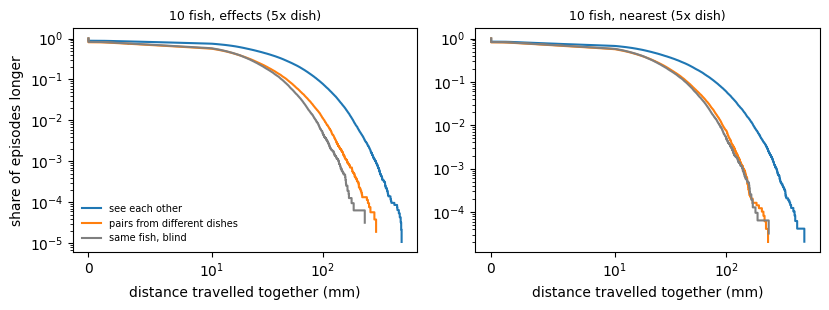

In [ ]:
MFish.plot_cotravel();

### 2.6 Next to the literature

Same definitions, nulls recomputed from our simulations. The papers' fish are real conspecifics of known age; ours are a
dot-trained model, and the age of the recorded fish is unknown (the stimulus protocol and the real dot response suggest
juveniles, roughly 2–3 weeks).

In [ ]:
MFish.literature_table(S)

                                                                                                                                                                                  value
source                                         measure                                                                                                                                 
Harpaz et al. 2021 (groups of 5/10, real fish) D = ln(NN / NN shuffled)          7 dpf: +0.075 +- 0.067, 14 dpf: -0.097 +- 0.083, 21 dpf: -0.550 +- 0.240, 7 dpf, dark: +0.010 +- 0.068
model: 5 fish, effects                         D = ln(NN / NN shuffled)                                                                     -0.298 +- 0.086 (mean +- SD over 20 dishes)
model: 5 fish, nearest                         D = ln(NN / NN shuffled)                                                                     -0.285 +- 0.093 (mean +- SD over 20 dishes)
model: 10 fish, effects                        D = ln(NN / NN shuffled)         

### 2.7 Kinematics and inputs

Each fish against itself blind (same start, latent, random stream), next to what real fish do when moving dots appear
(moving blocks vs pauses, per fish, median [10th, 90th percentile]).

In [ ]:
MFish.kin_table(S)

                                                 bout rate ratio     median step ratio mean |turn| difference (deg) near-straight share difference
condition                                                                                                                                         
REAL fish: moving dots vs pause (per fish)  0.931 [0.865, 1.079]  1.031 [0.914, 1.075]         4.273 [0.300, 6.845]         -0.002 [-0.010, 0.009]
pairs                                       0.958 [0.915, 0.999]  1.042 [0.988, 1.105]        1.372 [-0.416, 5.184]         -0.002 [-0.008, 0.007]
5 fish, effects                             0.904 [0.867, 0.975]  1.095 [1.037, 1.185]        1.973 [-0.752, 6.237]          0.000 [-0.011, 0.008]
5 fish, nearest                             0.933 [0.893, 0.980]  1.070 [1.021, 1.145]        1.886 [-0.033, 6.131]         -0.001 [-0.010, 0.008]
10 fish, effects                            0.879 [0.833, 0.945]  1.160 [1.071, 1.267]        2.400 [-1.154, 6.215]   

What the fish were shown (provider log, readout window).

In [ ]:
MFish.ood_table(S)

                                     bouts with a neighbour in view  neighbours in view  dot groups per bout  bouts with > 2 groups  bouts with a pool > 8  bouts with a pooled group  nearest group (mm, median)  nearest group > 44 mm  a group outside the dish
pairs                                                         1.000               1.000                1.000                  0.000                  0.000                      0.000                      15.527                  0.059                     0.000
5 fish, effects                                               1.000               4.000                1.621                  0.111                  0.000                      0.993                      12.354                  0.006                     0.000
5 fish, nearest                                               1.000               3.999                1.954                  0.230                  0.000                      0.981                      12.469              

### 2.8 Videos

Each video shows one dish: **left**, the 10 fish seeing each other; **right**, the same 10 fish (same starts, latents
and random streams) blind. Bouts are drawn as 0.2 s glides (the model's bouts are instantaneous) with the last 4 s as a
trail; the 5× videos are zoomed onto the fish (the width of the view is printed in the corner). (1) the dish where all
10 fish first come together from a scattered start; (2) the stretch where a shoal's centre travels furthest; (3) training
dish: the 90 s with the smallest nearest-neighbour distance after minute 5. The videos play when the notebook is opened
from the `Model` folder; stills of the same windows are below.

**5x dish: a shoal forms (all 10 together from 2.7 min) and moves off** — 10 fish, effects (5x dish), dish 18, 0.0–4.7 min (`multi_fish/videos/1_formation_A5_N10_effects_dish18_0-284s.mp4`)

<video src="multi_fish/videos/1_formation_A5_N10_effects_dish18_0-284s.mp4" controls width="980"></video>

**5x dish: a shoal travelling together** — 10 fish, effects (5x dish), dish 9, 49.3–52.3 min (`multi_fish/videos/2_travel_A5_N10_effects_dish9_2960-3140s.mp4`)

<video src="multi_fish/videos/2_travel_A5_N10_effects_dish9_2960-3140s.mp4" controls width="980"></video>

**training dish: the tightest 90 s** — 10 fish, effects, dish 0, 5.4–6.9 min (`multi_fish/videos/3_training_dish_A1_N10_effects_dish0_326-416s.mp4`)

<video src="multi_fish/videos/3_training_dish_A1_N10_effects_dish0_326-416s.mp4" controls width="980"></video>

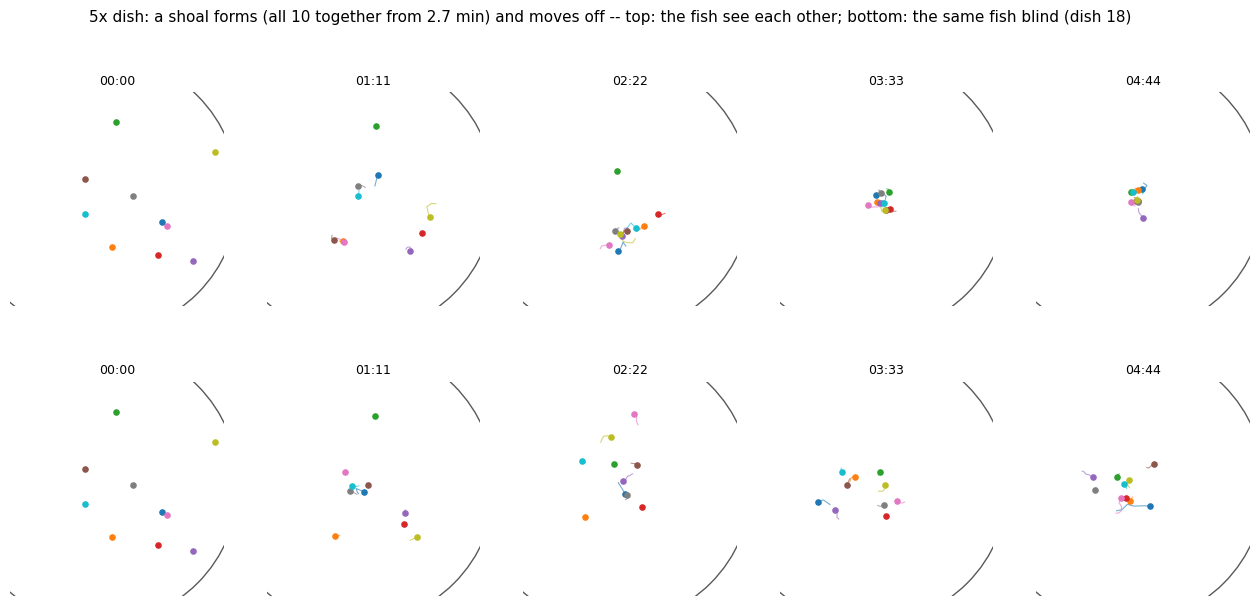

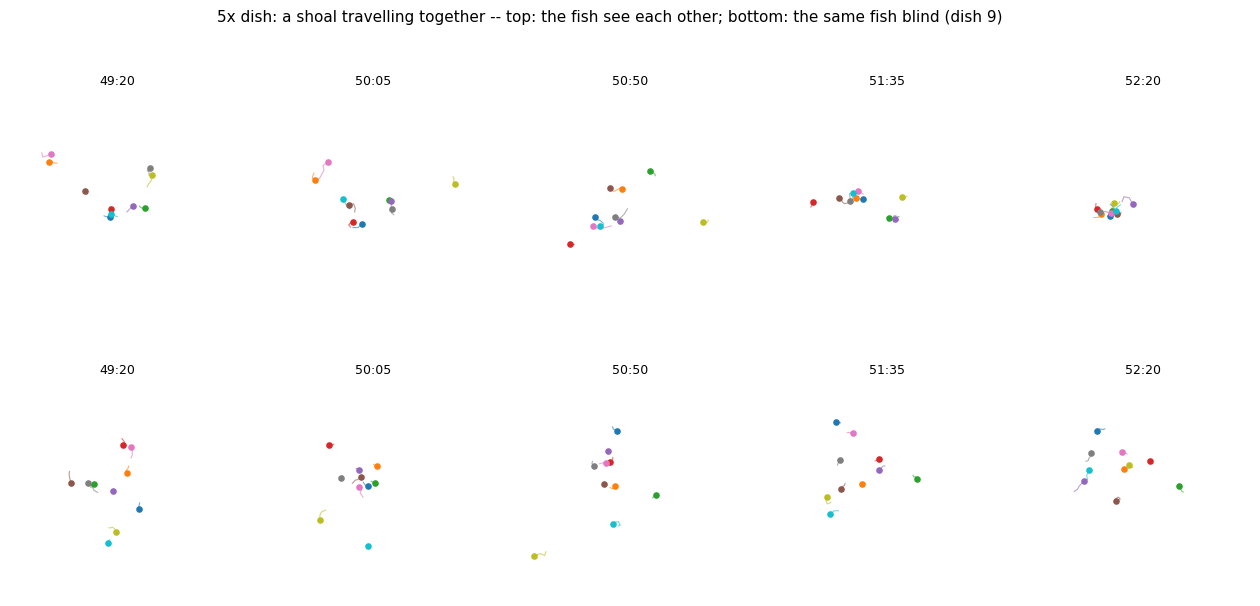

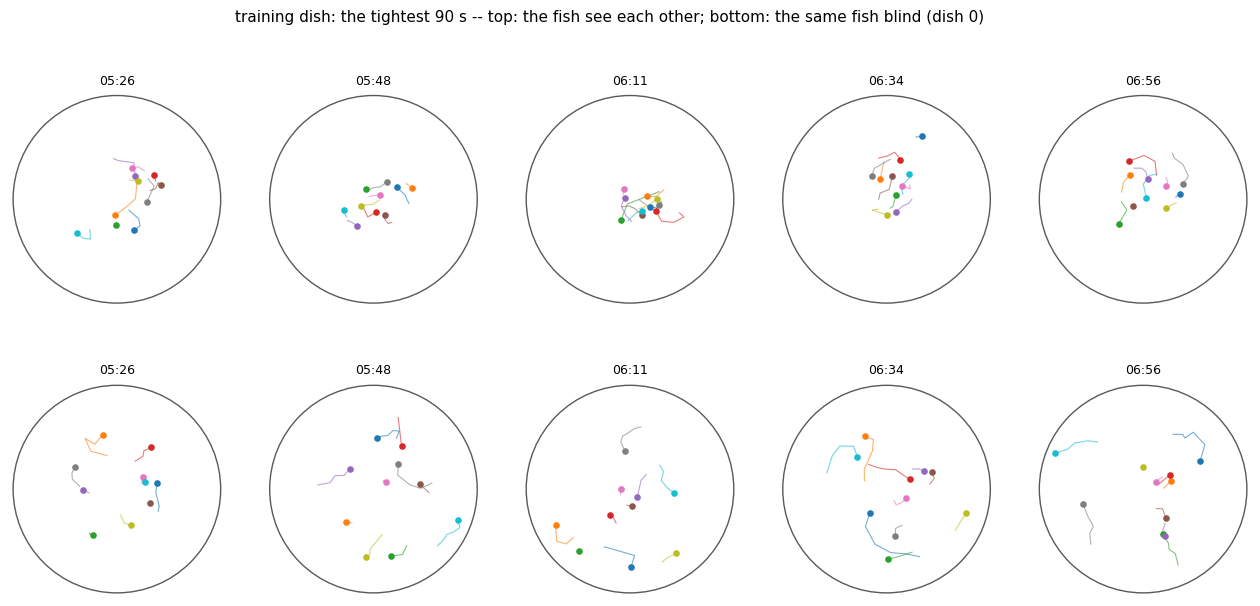

In [ ]:
import matplotlib.pyplot as plt
V = json.load(open(MFish.VIDEO_DIR / "videos.json"))
for mp4, c, g, t0, t1, title in V:   # stills of each video window: top = the fish see each other, bottom = the same fish blind
    view = MFish.view_of([(c, g), (MFish.blind_of(c), g)], t0, t1)
    fig, ax = plt.subplots(2, 5, figsize=(16, 6.9))
    MFish.snapshot(c, g, list(np.linspace(t0, t1, 5)), ax[0], view=view)
    MFish.snapshot(c, g, list(np.linspace(t0, t1, 5)), ax[1], blind=True, view=view)
    fig.suptitle(f"{title} -- top: the fish see each other; bottom: the same fish blind (dish {g})", fontsize=11)

<a id="repulsion"></a>
## 3. With repulsion: F + the turn-away term fitted to the Larsch screen data

**What changes.** The shoals of section 2 are made by F, which has no short-range repulsion: on the Larsch lab's
single-dot screen (Final_report_extra_data.ipynb, section 2) the models keep turning *toward* a dot closer than 4 mm,
where real fish turn away. Section 4 of that notebook fits a fixed-form turn-away to those data (network and profile
correction untouched; fitted on half the screen's clutches, tested on the other half) and retains **F + turn**: a turn
away from any dot within reach, *s* = −0.3 Σ_j sin φ_j σ((*r_c* − *d_j*)/1 mm) with *r_c* = 8 mm (seed 0) / 9 mm
(seed 101). It passes on the held-out clutches and leaves the likelihood and AUC on our data unchanged.

**How it enters the shoal.** Every simulated fish adds the term for **each neighbour individually** (the individual
positions, `FishView.dots`), while attraction still comes through the dot-group code exactly as in section 2. Same
scenes, start poses, latents and random streams as F. The blind pools are F's: a blind fish sees no neighbour, so the
term never acts (checked: byte-identical).

**Expected, written before the runs.** (1) Fewer close contacts — the share of time a fish's nearest neighbour is within
a few mm should drop clearly. (2) Aggregation (attraction index, D, largest cluster, co-travel) similar or slightly
weaker, with the nearest-neighbour distance shifted up by a few mm — on the screen data the term did not make the fish
hover near the dot. (3) No polarisation: the term carries no heading. (4) Neighbours sum and a fish is a larger stimulus
than a 2 mm dot, so the effect may be stronger than on the screen.

### 3.1 F, F + turn and F + turn + step, scene by scene

In [ ]:
import json, numpy as np, pandas as pd
import multi_fish as MFish
SR = json.load(open(MFish.OUT / "summary_rep.json"))
CC, BASE = SR["contacts"], SR["rep_base"]
rows = []
for rc, bc in BASE.items():
    seed = "101" if "s101" in rc else "0"
    scene = "pairs" if "pairs" in rc else ("10 fish, 5x dish" if "A5" in rc else "10 fish, training dish")
    sc = "reps_" + rc[len("rep_"):]
    has_s = sc in CC
    def add(measure, f, r, q=None, nd=3):
        row = dict(scene=scene, seed=seed, measure=measure, F=round(f, nd), **{"F + turn": round(r, nd)})
        if has_s and q is not None:
            row["F + turn + step"] = round(q, nd)
        rows.append(row)
    for k, lab in (("share_nn_le_2mm", "nearest neighbour <= 2 mm (share of time)"),
                   ("share_nn_le_4mm", "nearest neighbour <= 4 mm"), ("share_nn_le_6mm", "nearest neighbour <= 6 mm"),
                   ("share_nn_le_10mm", "nearest neighbour <= 10 mm"), ("nn_p10", "nearest neighbour, 10th percentile (mm)"),
                   ("nn_median", "nearest neighbour, median (mm)")):
        add(lab, CC[bc][k], CC[rc][k], CC[sc][k] if has_s else None, 3 if "share" in k else 1)
    if rc in SR["pairs"] and bc in SR["pairs"]:
        f, r = SR["pairs"][bc]["coupled"], SR["pairs"][rc]["coupled"]
        q = SR["pairs"].get(sc, {}).get("coupled")
        add("attraction index (pairs)", f["ai_mean"], r["ai_mean"], q and q["ai_mean"])
        add("pair within 25 mm (share of time)", f["share_within_25mm"], r["share_within_25mm"], q and q["share_within_25mm"])
    if rc in SR["groups"] and bc in SR["groups"]:
        f, r = SR["groups"][bc], SR["groups"][rc]
        q = SR["groups"].get(sc)
        add("D (log NND / shuffled; < 0 = shoaling)", f["D_mean"], r["D_mean"], q and q["D_mean"])
        add("largest cluster (fish within 25 mm)", f["big_mean"], r["big_mean"], q and q["big_mean"], 2)
        add("half the fish together (share of time)", f["share_half_together"], r["share_half_together"],
            q and q["share_half_together"])
        add("polarisation (|mean heading|)", f["pol"], r["pol"], q and q["pol"])
    if rc in SR["cotravel"] and bc in SR["cotravel"]:
        q = SR["cotravel"].get(sc)
        add("co-travel episodes per pair-hour", SR["cotravel"][bc]["coupled"]["eps_per_pair_hour"],
            SR["cotravel"][rc]["coupled"]["eps_per_pair_hour"], q and q["coupled"]["eps_per_pair_hour"], 2)
T3 = pd.DataFrame(rows).set_index(["scene", "seed", "measure"])
T3

                                                                             F  F + turn  F + turn + step
scene                  seed measure                                                                      
pairs                  0    nearest neighbour <= 2 mm (share of time)    0.014     0.012            0.010
                            nearest neighbour <= 4 mm                    0.053     0.046            0.045
                            nearest neighbour <= 6 mm                    0.119     0.103            0.106
                            nearest neighbour <= 10 mm                   0.287     0.273            0.283
                            nearest neighbour, 10th percentile (mm)      5.500     5.900            5.900
                            nearest neighbour, median (mm)              14.900    15.200           14.700
                            attraction index (pairs)                     0.346     0.331            0.354
                            pair within 25 mm 

### 3.2 Nearest-neighbour distance

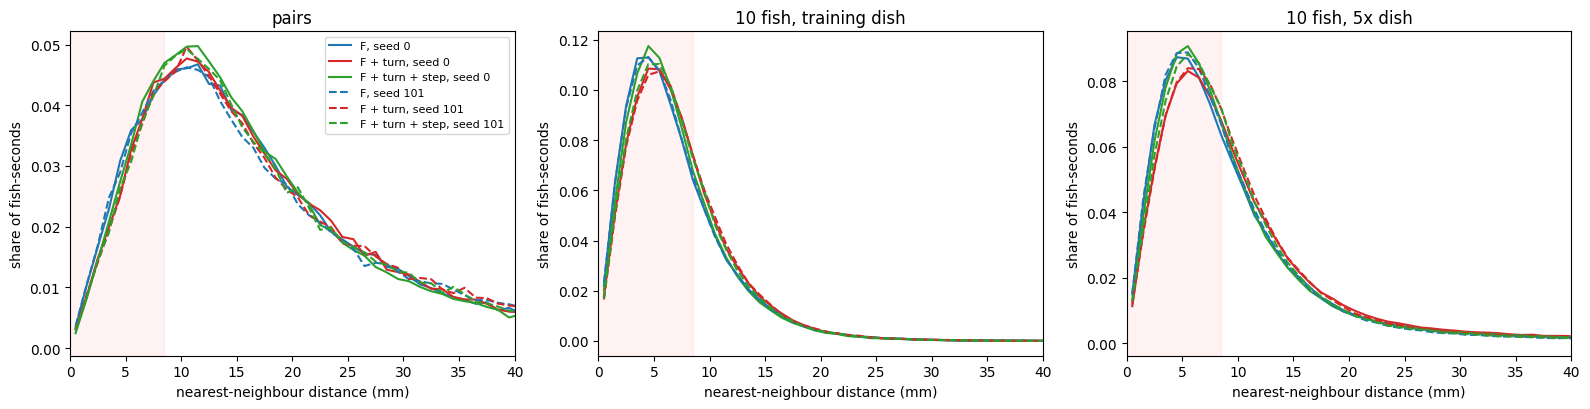

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2), sharey=False)
order = [("A1_pairs", "pairs"), ("A1_N10_effects", "10 fish, training dish"), ("A5_N10_effects", "10 fish, 5x dish")]
x = np.arange(60) + 0.5
for a, (stem, title) in zip(ax, order):
    for seed, ls in (("", "-"), ("s101_", "--")):
        for c, col, lab in ((seed + stem, "C0", "F"), ("rep_" + seed + stem, "C3", "F + turn"),
                            ("reps_" + seed + stem, "C2", "F + turn + step")):
            if c not in CC:
                continue
            h = np.array(CC[c]["hist"], float); h = h / h.sum()
            a.plot(x, h, ls, color=col, label=f"{lab}, seed {'101' if seed else '0'}")
    a.axvspan(0, 8.5, color="r", alpha=.05); a.set_xlim(0, 40); a.set_title(title)
    a.set_xlabel("nearest-neighbour distance (mm)"); a.set_ylabel("share of fish-seconds")
ax[0].legend(fontsize=8); plt.tight_layout()

### 3.3 The same dish with and without repulsion

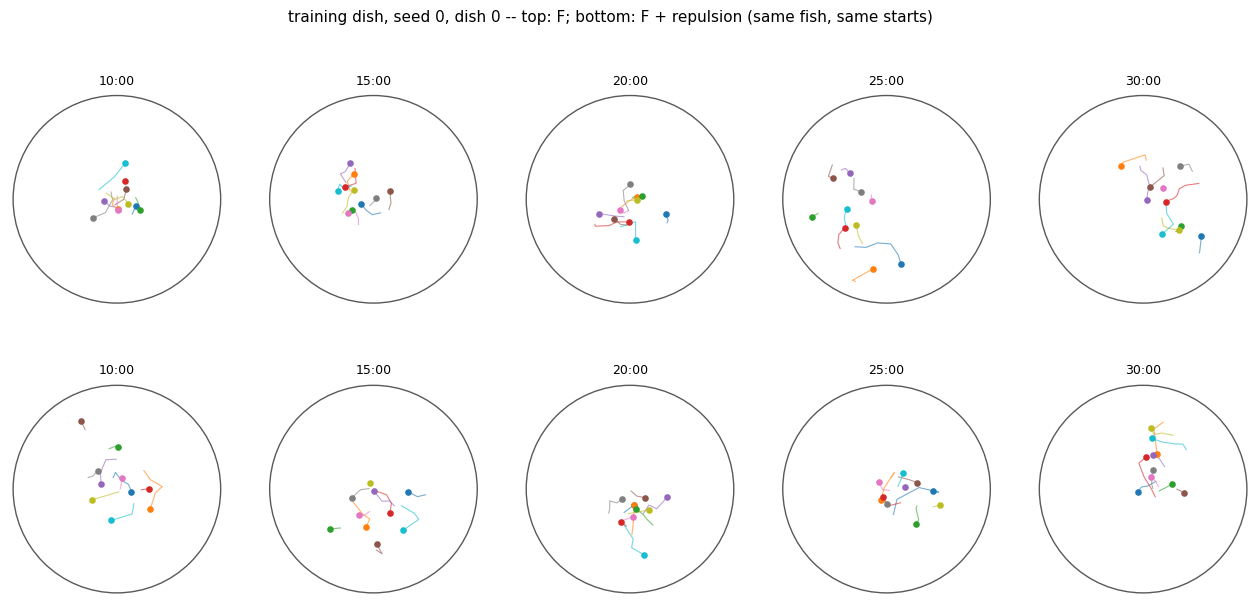

In [ ]:
import matplotlib.pyplot as plt
c0, c1, g = "A1_N10_effects", "rep_A1_N10_effects", 0     # the same dish, the same 10 fish (starts, latents, streams)
times = list(np.linspace(600, 1800, 5))
view = MFish.view_of([(c0, g), (c1, g)], times[0], times[-1])
fig, ax = plt.subplots(2, 5, figsize=(16, 6.9))
MFish.snapshot(c0, g, times, ax[0], view=view)
MFish.snapshot(c1, g, times, ax[1], view=view)
fig.suptitle("training dish, seed 0, dish 0 -- top: F; bottom: F + repulsion (same fish, same starts)", fontsize=11)

### 3.4 Verdict

**Repulsion changes the shoals, but only modestly: fewer close contacts, the same shoaling.** Every prediction written
before the runs holds in direction, at both seeds; the size is small.
- **Close contacts drop by a fifth.** In groups of 10, the time a fish's nearest neighbour is within 4 mm falls
  29 → 24–25 % (training dish) and 20 → 16 % (5× dish), within 2 mm 8.5 → 6.6–6.9 % and 5.7 → 4.4 %; the nearest
  neighbour's median moves out by 0.5–0.7 mm (5.9 → 6.4 mm; 7.6–7.8 → 8.3–8.4 mm). Pairs: within 4 mm 5.3–5.5 → 4.5–4.6 %.
- **Shoaling is unchanged.** Pair attraction index 0.35 → 0.33 (seed 0) and 0.32 → 0.32 (seed 101), intervals
  overlapping; D −0.20 → −0.17 and −0.18 → −0.16 in the training dish (slightly weaker), −0.76 → −0.75 and −0.71 → −0.70
  in the 5× dish; largest cluster and co-travel (≈123 episodes per pair-hour) unchanged.
- **No polarisation** (0.30–0.31 against 0.28 for shuffled groups, as without the term): the term carries no heading.

**Why so small.** The term was fitted to a 2 mm dot under the fish and reaches ~8–9 mm; a neighbour inside a dense group
is also pulled back by the attraction of every other neighbour (the group code), and the fish still approach without
braking (Final_report_extra_data, section 4: the backing off and the hovering are not reproduced). The groups stay
tight — in the training dish the median nearest neighbour is ~6 mm, about one body length of a larva.

**For the report.** The over-clustering that F's shoals show is reduced but not removed by the repulsion the screen data
support; a stronger spacing would need either the missing backing off (being diagnosed) or a larger reach for a
neighbour than for a 2 mm dot — not measurable from single-dot data.

**Adding the step term (F + turn + step, Model 50) partly undoes the spacing gain.** Shorter steps near any neighbour
make a fish linger where it already is, so close contacts come back part of the way: nearest neighbour within 4 mm in
groups of 10, training dish, F 29 % → F + turn 24.5 % → F + turn + step 27 % (seed 0) and 29 → 24 → 25 % (seed 101); 5×
dish 20 → 16 → 18.6 % and 20 → 16 → 17.5 %; median nearest neighbour 5.9 → 6.4 → 6.0 mm. Shoaling is again unchanged
(pair attraction 0.35 | 0.32 for all three; D −0.20 → −0.17 → −0.16 in the training dish), co-travel in the 5× dish drops
by ~8 % (123 → 114–116 episodes per pair-hour: the slower steps near neighbours shorten the joint trips), no
polarisation. For the shoal, **F + turn is the better of the two**: the step term, which fixes the single-dot backing
off, works against spacing when every neighbour slows the fish down.